In [1]:
!pip install --upgrade keras

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 11.5 MB/s eta 0:00:00
  Attempting uninstall: keras
    Found existing installation: keras 2.15.0
    Uninstalling keras-2.15.0:
      Successfully uninstalled keras-2.15.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tensorflow 2.15.0 requires keras<2.16,>=2.15.0, but you have keras 3.0.4 which is incompatible.


In [2]:
import keras

print(keras.__version__)

3.0.4


In [3]:
from google.colab import drive
drive.mount("/content/drive")


Mounted at /content/drive



Epoch 1: val_accuracy improved from -inf to 0.73188, saving model to best_model.keras

Epoch 2: val_accuracy did not improve from 0.73188

Epoch 3: val_accuracy did not improve from 0.73188

Epoch 4: val_accuracy did not improve from 0.73188

Epoch 5: val_accuracy did not improve from 0.73188

Epoch 6: val_accuracy improved from 0.73188 to 0.75362, saving model to best_model.keras

Epoch 7: val_accuracy did not improve from 0.75362

Epoch 8: val_accuracy did not improve from 0.75362

Epoch 9: val_accuracy improved from 0.75362 to 0.78261, saving model to best_model.keras

Epoch 10: val_accuracy did not improve from 0.78261

Epoch 11: val_accuracy did not improve from 0.78261

Epoch 12: val_accuracy did not improve from 0.78261

Epoch 13: val_accuracy did not improve from 0.78261

Epoch 14: val_accuracy did not improve from 0.78261

Epoch 15: val_accuracy did not improve from 0.78261
訓練資料集的準確度 = 0.78
測試資料集的準確度 = 0.73


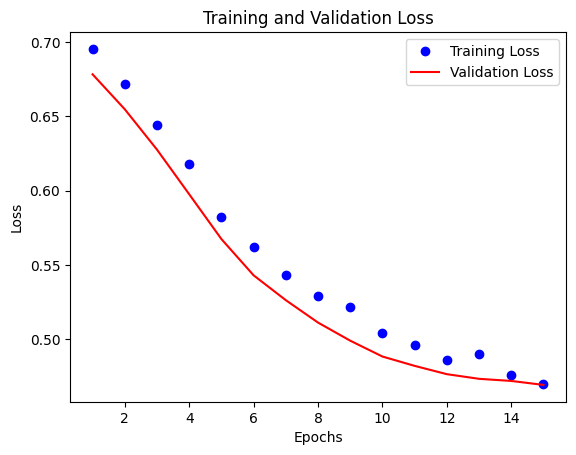

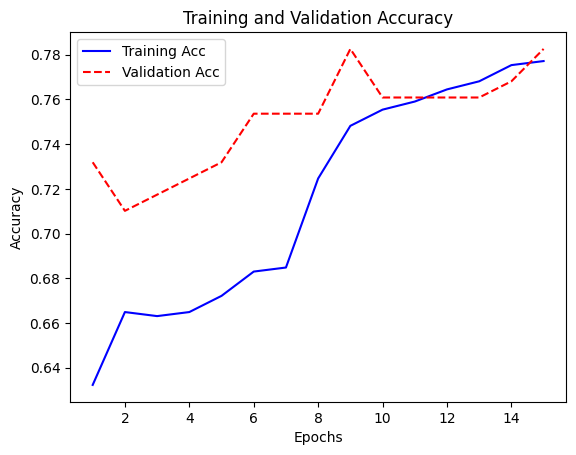

In [4]:
import numpy as np
import pandas as pd
from keras import Sequential
from keras.layers import Input, Dense
from keras.utils import to_categorical

np.random.seed(10)  # 指定亂數種子
# 載入糖尿病資料集
df = pd.read_csv("/content/drive/My Drive/Python/diabetes.csv")
dataset = df.values
np.random.shuffle(dataset)  # 使用亂數打亂資料
# 分割成特徵資料和標籤資料
X = dataset[:, 0:8]
y = dataset[:, 8]
# 特徵標準化
X -= X.mean(axis=0)
X /= X.std(axis=0)
# One-hot編碼
y = to_categorical(y)
# 分割訓練和測試資料集
X_train, y_train = X[:690], y[:690]     # 訓練資料前690筆
X_test, y_test = X[690:], y[690:]       # 測試資料後78筆
# 定義模型
model = Sequential()
model.add(Input(shape=(8,)))
model.add(Dense(8, activation="relu"))
model.add(Dense(8, activation="relu"))
model.add(Dense(2, activation="softmax"))
# model.summary()   # 顯示模型摘要資訊
# 編譯模型
model.compile(loss="binary_crossentropy", optimizer="adam",
              metrics=["accuracy"])
# 訓練模型
from keras.callbacks import ModelCheckpoint
# 建立 ModelCheckpoint 物件
mc = ModelCheckpoint("best_model.keras", monitor="val_accuracy",
                     mode="max", verbose=1,
                     save_best_only=True)
history = model.fit(X_train, y_train, validation_split=0.2,
          epochs=15, batch_size=10,
          verbose=0, callbacks=[mc])
# 評估模型
loss, accuracy = model.evaluate(X_train, y_train, verbose=0)
print("訓練資料集的準確度 = {:.2f}".format(accuracy))
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
print("測試資料集的準確度 = {:.2f}".format(accuracy))
# 顯示訓練和驗證損失圖表
import matplotlib.pyplot as plt

loss = history.history["loss"]
epochs = range(1, len(loss)+1)
val_loss = history.history["val_loss"]
plt.plot(epochs, loss, "bo", label="Training Loss")
plt.plot(epochs, val_loss, "r", label="Validation Loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()
# 顯示訓練和驗證準確度
acc = history.history["accuracy"]
epochs = range(1, len(acc)+1)
val_acc = history.history["val_accuracy"]
plt.plot(epochs, acc, "b-", label="Training Acc")
plt.plot(epochs, val_acc, "r--", label="Validation Acc")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()

In [6]:
import numpy as np
import pandas as pd
from keras.models import load_model
from keras.utils import to_categorical

np.random.seed(10)  # 指定亂數種子
# 載入糖尿病資料集
df = pd.read_csv("/content/drive/My Drive/Python/diabetes.csv")
dataset = df.values
np.random.shuffle(dataset)  # 使用亂數打亂資料
# 分割成特徵資料和標籤資料
X = dataset[:, 0:8]
y = dataset[:, 8]
# 特徵標準化
X -= X.mean(axis=0)
X /= X.std(axis=0)
# One-hot編碼
y = to_categorical(y)
# 分割訓練和測試資料集
X_train, y_train = X[:690], y[:690]     # 訓練資料前690筆
X_test, y_test = X[690:], y[690:]       # 測試資料後78筆
# 定義模型
model = model = load_model("best_model.keras")
# 編譯模型
model.compile(loss="binary_crossentropy", optimizer="adam",
              metrics=["accuracy"])
# 評估模型
loss, accuracy = model.evaluate(X_train, y_train, verbose=0)
print("訓練資料集的準確度 = {:.2f}".format(accuracy))
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
print("測試資料集的準確度 = {:.2f}".format(accuracy))


訓練資料集的準確度 = 0.76
測試資料集的準確度 = 0.76



Epoch 1: val_accuracy improved from -inf to 0.68841, saving model to best_model-01-0.69.keras

Epoch 2: val_accuracy improved from 0.68841 to 0.77536, saving model to best_model-02-0.78.keras

Epoch 3: val_accuracy did not improve from 0.77536

Epoch 4: val_accuracy improved from 0.77536 to 0.78261, saving model to best_model-04-0.78.keras

Epoch 5: val_accuracy did not improve from 0.78261

Epoch 6: val_accuracy improved from 0.78261 to 0.78986, saving model to best_model-06-0.79.keras

Epoch 7: val_accuracy improved from 0.78986 to 0.79710, saving model to best_model-07-0.80.keras

Epoch 8: val_accuracy did not improve from 0.79710

Epoch 9: val_accuracy improved from 0.79710 to 0.81159, saving model to best_model-09-0.81.keras

Epoch 10: val_accuracy did not improve from 0.81159

Epoch 11: val_accuracy did not improve from 0.81159

Epoch 12: val_accuracy did not improve from 0.81159

Epoch 13: val_accuracy did not improve from 0.81159

Epoch 14: val_accuracy did not improve from 0.

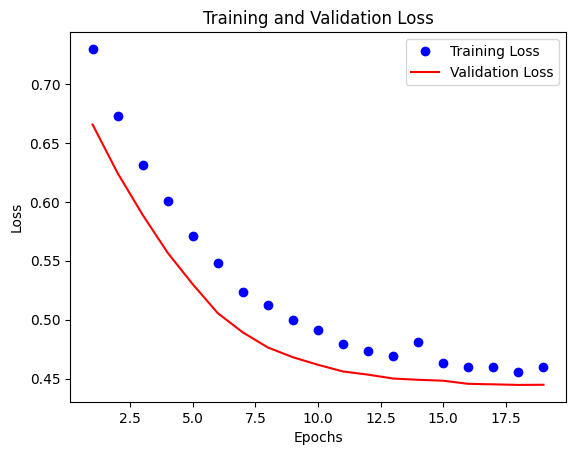

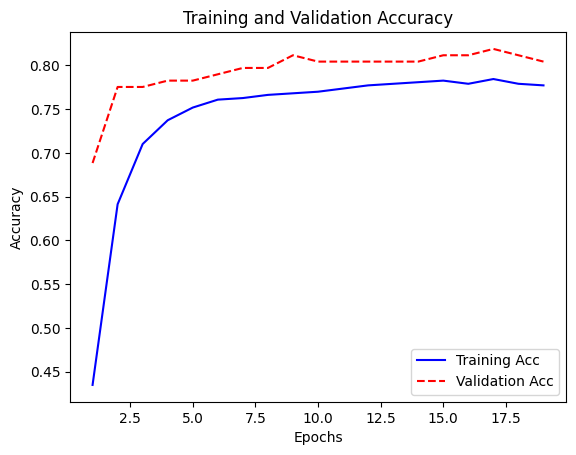

In [7]:
import numpy as np
import pandas as pd
from keras import Sequential
from keras.layers import Input, Dense
from keras.utils import to_categorical

np.random.seed(10)  # 指定亂數種子
# 載入糖尿病資料集
df = pd.read_csv("/content/drive/My Drive/Python/diabetes.csv")
dataset = df.values
np.random.shuffle(dataset)  # 使用亂數打亂資料
# 分割成特徵資料和標籤資料
X = dataset[:, 0:8]
y = dataset[:, 8]
# 特徵標準化
X -= X.mean(axis=0)
X /= X.std(axis=0)
# One-hot編碼
y = to_categorical(y)
# 分割訓練和測試資料集
X_train, y_train = X[:690], y[:690]     # 訓練資料前690筆
X_test, y_test = X[690:], y[690:]       # 測試資料後78筆
# 定義模型
model = Sequential()
model.add(Input(shape=(8,)))
model.add(Dense(8, activation="relu"))
model.add(Dense(8, activation="relu"))
model.add(Dense(2, activation="softmax"))
# model.summary()   # 顯示模型摘要資訊
# 編譯模型
model.compile(loss="binary_crossentropy", optimizer="adam",
              metrics=["accuracy"])
# 訓練模型
from keras.callbacks import EarlyStopping
# 建立 EarlyStopping 物件
es = EarlyStopping(monitor="val_loss", mode="min",
                   verbose=1)

from keras.callbacks import ModelCheckpoint
# 建立 ModelCheckpoint 物件
filename = "best_model-{epoch:02d}-{val_accuracy:.2f}.keras"
mc = ModelCheckpoint(filename, monitor="val_accuracy",
                     mode="max", verbose=1,
                     save_best_only=True)
history = model.fit(X_train, y_train, validation_split=0.2,
          epochs=20, batch_size=10,
          verbose=0, callbacks=[es, mc])
# 評估模型
loss, accuracy = model.evaluate(X_train, y_train, verbose=0)
print("訓練資料集的準確度 = {:.2f}".format(accuracy))
loss, accuracy = model.evaluate(X_test, y_test, verbose=0)
print("測試資料集的準確度 = {:.2f}".format(accuracy))
# 顯示訓練和驗證損失圖表
import matplotlib.pyplot as plt

loss = history.history["loss"]
epochs = range(1, len(loss)+1)
val_loss = history.history["val_loss"]
plt.plot(epochs, loss, "bo", label="Training Loss")
plt.plot(epochs, val_loss, "r", label="Validation Loss")
plt.title("Training and Validation Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.show()
# 顯示訓練和驗證準確度
acc = history.history["accuracy"]
epochs = range(1, len(acc)+1)
val_acc = history.history["val_accuracy"]
plt.plot(epochs, acc, "b-", label="Training Acc")
plt.plot(epochs, val_acc, "r--", label="Validation Acc")
plt.title("Training and Validation Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.show()